# Paper figure: cross-app nearest neighbors

This qualitative retrieval figure uses representative ENRICO queries and searches the complete local RICO embedding collection. Candidates from the query app are excluded, so visual or structural matches cannot be explained by app identity. Similarities are exact cosine similarities in the original 4,096-dimensional embedding space—no UMAP distances are used.

In [1]:
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm.auto import tqdm

from paper_embedding_analysis import (DEFAULT_EMBEDDINGS_DIR, LAYOUTS_DIR, available_embedding_ids, load_embedding_file, load_embeddings, output_dir, package_from_layout, read_enrico_topics)

sns.set_theme(context="paper", style="white", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
QUERY_TOPICS = ("login", "list", "settings", "profile")
TOP_K = 3
BATCH_SIZE = 512
WORKERS = 12
OUTPUT_DIR = output_dir("paper_cross_app_nearest_neighbors")

## Choose reproducible representative queries

Within each requested ENRICO topic, the medoid is the screen with the highest mean cosine similarity to other matched screens of that topic. This avoids hand-picking unusually attractive examples.

In [3]:
topics = read_enrico_topics()
available = available_embedding_ids(DEFAULT_EMBEDDINGS_DIR)
pool = topics[topics["screen_id"].isin(available) & topics["topic"].isin(QUERY_TOPICS)].copy()
ids, topic_vectors = load_embeddings(pool["screen_id"], DEFAULT_EMBEDDINGS_DIR, description="Loading ENRICO query pool")
id_to_vector = dict(zip(ids, topic_vectors))
query_rows = []
for topic in QUERY_TOPICS:
    topic_ids = pool.loc[pool["topic"] == topic, "screen_id"].tolist()
    matrix = np.stack([id_to_vector[screen_id] for screen_id in topic_ids])
    medoid_index = int(np.argmax((matrix @ matrix.T).mean(axis=1)))
    screen_id = topic_ids[medoid_index]
    package = package_from_layout(LAYOUTS_DIR / f"{screen_id}.json")
    query_rows.append({"topic": topic, "screen_id": screen_id, "package": package, "embedding": id_to_vector[screen_id]})
queries = pd.DataFrame(query_rows)
query_matrix = np.stack(queries["embedding"])
display(queries.drop(columns="embedding"))

Loading ENRICO query pool: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 518/518 [00:00<00:00, 1798.09it/s]


,topic,screen_id,package
0,login,20910,com.kc.pottytime
1,list,22726,com.globalegrow.app.dresslily
2,settings,61678,com.ghostwording.stickerbliss
3,profile,10863,com.jardogs.fmhmobile


## Exact cross-app search

The scan is batched to keep memory bounded. It reads every genuine one-token average-pooled embedding and retains only the best candidates from a different package.

In [4]:
candidate_paths = sorted(DEFAULT_EMBEDDINGS_DIR.glob("*.npz"), key=lambda p: int(p.stem))
best = {i: [] for i in range(len(queries))}

def load_candidate(path):
    screen_id = int(path.stem)
    package = package_from_layout(LAYOUTS_DIR / f"{screen_id}.json")
    return screen_id, package, load_embedding_file(path)

with ThreadPoolExecutor(max_workers=WORKERS) as executor:
    for start in tqdm(range(0, len(candidate_paths), BATCH_SIZE), desc="Searching all RICO screens"):
        records = list(executor.map(load_candidate, candidate_paths[start:start + BATCH_SIZE]))
        batch_ids = np.array([record[0] for record in records])
        batch_packages = [record[1] for record in records]
        batch_matrix = np.stack([record[2] for record in records])
        similarities = batch_matrix @ query_matrix.T
        for query_index, query in queries.iterrows():
            valid = [i for i, package in enumerate(batch_packages) if batch_ids[i] != query.screen_id and package != query.package]
            local = sorted(valid, key=lambda i: similarities[i, query_index], reverse=True)[:TOP_K]
            best[query_index].extend((float(similarities[i, query_index]), int(batch_ids[i]), batch_packages[i]) for i in local)
            best[query_index] = sorted(best[query_index], reverse=True)[:TOP_K]

topic_lookup = topics.set_index("screen_id")["topic"].to_dict()
result_rows = []
for query_index, query in queries.iterrows():
    for rank, (similarity, screen_id, package) in enumerate(best[query_index], start=1):
        result_rows.append({"query_topic": query.topic, "query_id": query.screen_id, "query_package": query.package, "rank": rank, "neighbor_id": screen_id, "neighbor_package": package, "neighbor_enrico_topic": topic_lookup.get(screen_id), "cosine_similarity": similarity})
results = pd.DataFrame(result_rows)
display(results.style.format({"cosine_similarity": "{:.4f}"}))
results.to_csv(OUTPUT_DIR / "cross_app_nearest_neighbors.csv", index=False)

Searching all RICO screens: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 130/130 [01:18<00:00,  1.65it/s]


,query_topic,query_id,query_package,rank,neighbor_id,neighbor_package,neighbor_enrico_topic,cosine_similarity
0,login,20910,com.kc.pottytime,1,56226,com.healthifyme.basic,None,0.9652
1,login,20910,com.kc.pottytime,2,54415,com.thredup.android,None,0.9629
2,login,20910,com.kc.pottytime,3,61648,com.tru,None,0.9629
3,list,22726,com.globalegrow.app.dresslily,1,58141,com.globalegrow.app.rosewholesale,None,0.9823
4,list,22726,com.globalegrow.app.dresslily,2,15876,com.vinted,None,0.9761
5,list,22726,com.globalegrow.app.dresslily,3,58139,com.globalegrow.app.rosewholesale,None,0.9713
6,settings,61678,com.ghostwording.stickerbliss,1,46209,com.ghostwording.stickers,None,0.9791
7,settings,61678,com.ghostwording.stickerbliss,2,37429,com.scores365,None,0.9632
8,settings,61678,com.ghostwording.stickerbliss,3,44217,com.dietcoacher.sos,None,0.9604
9,profile,10863,com.jardogs.fmhmobile,1,57914,md.your,None,0.9676


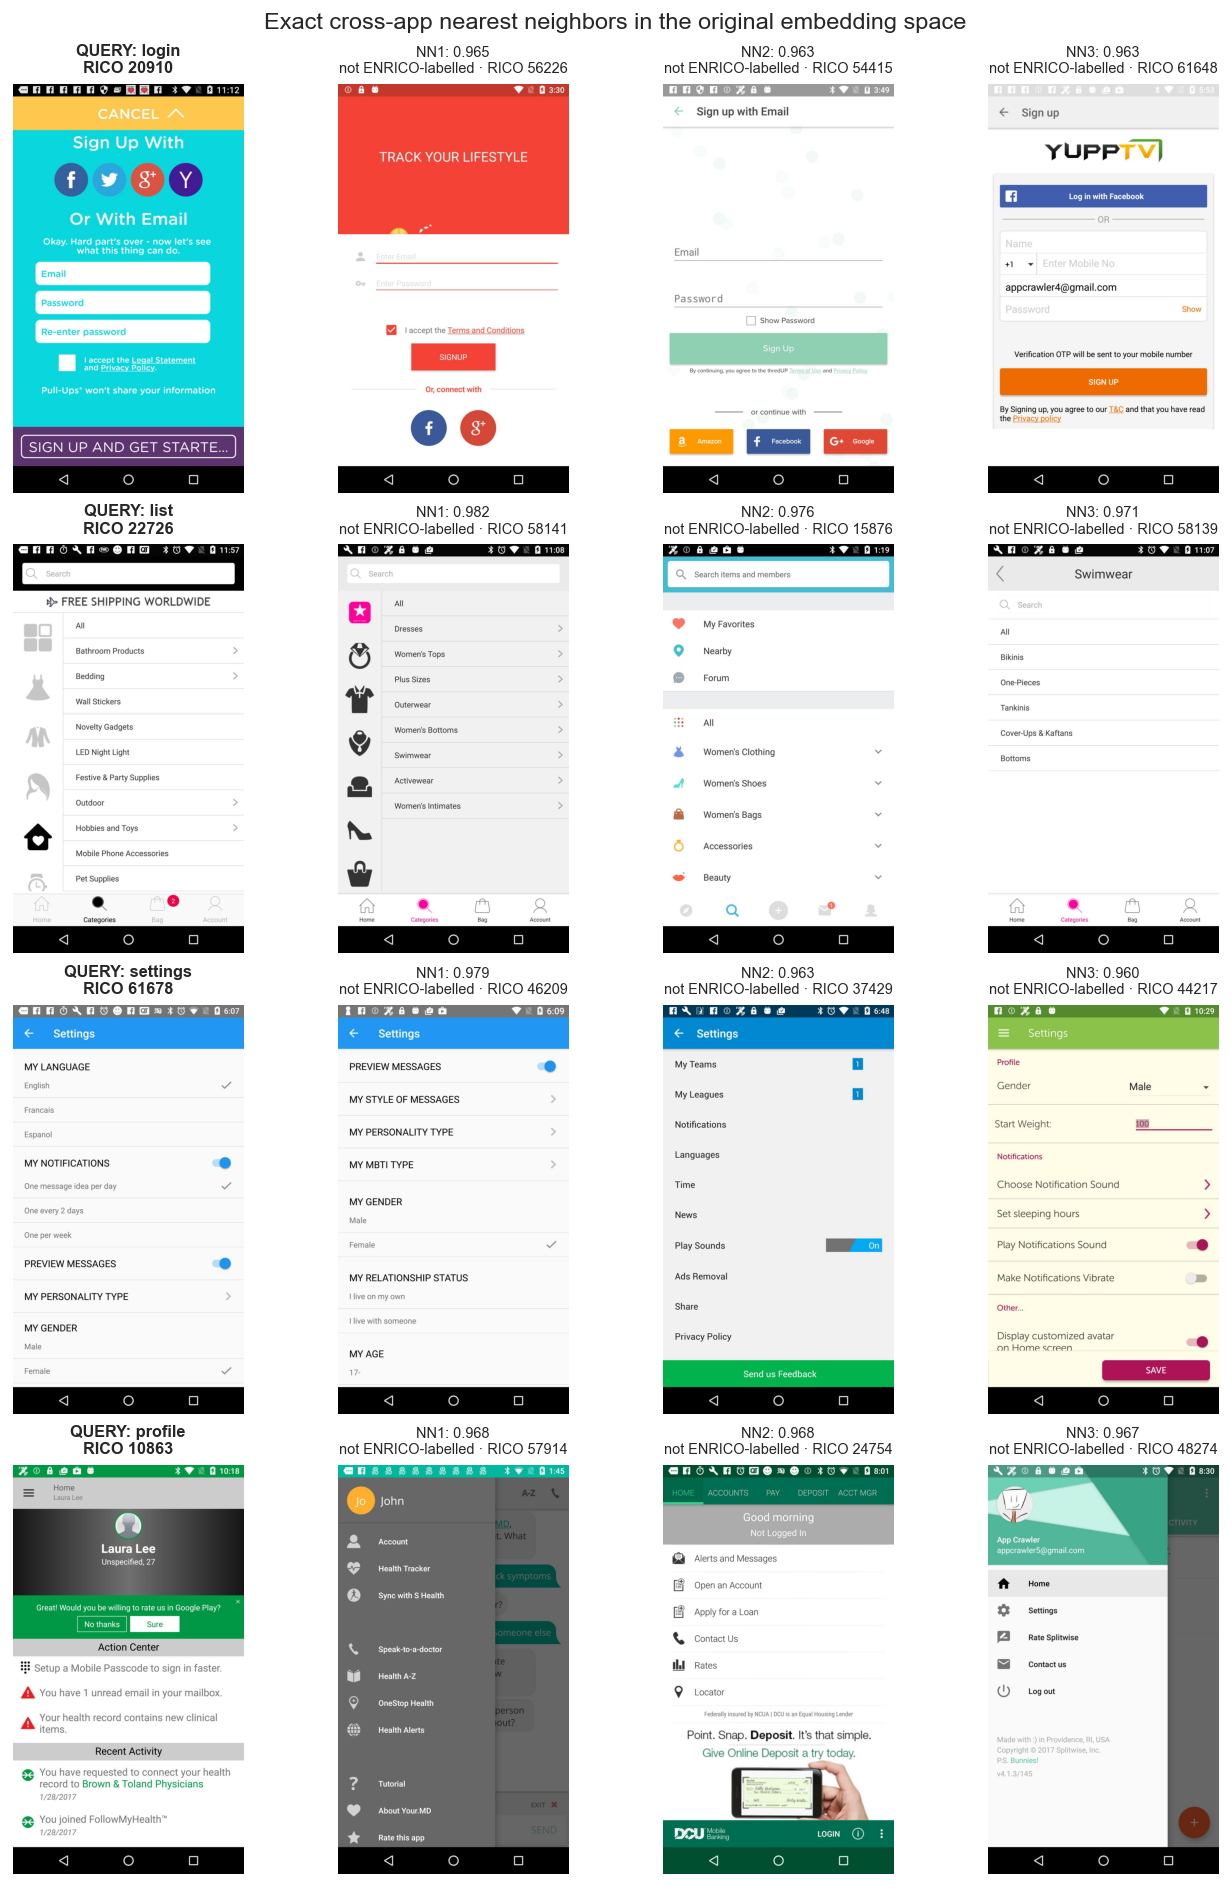

In [5]:
fig, axes = plt.subplots(len(queries), TOP_K + 1, figsize=(10, 3.6 * len(queries)), constrained_layout=True)
for row_index, query in queries.iterrows():
    query_image = plt.imread(LAYOUTS_DIR / f"{query.screen_id}.jpg")
    axes[row_index, 0].imshow(query_image)
    axes[row_index, 0].set_title(f"QUERY: {query.topic}\nRICO {query.screen_id}", fontsize=9, weight="bold")
    query_results = results[results["query_id"] == query.screen_id].sort_values("rank")
    for column, neighbor in enumerate(query_results.itertuples(), start=1):
        neighbor_image = plt.imread(LAYOUTS_DIR / f"{neighbor.neighbor_id}.jpg")
        axes[row_index, column].imshow(neighbor_image)
        topic_text = neighbor.neighbor_enrico_topic if pd.notna(neighbor.neighbor_enrico_topic) else "not ENRICO-labelled"
        axes[row_index, column].set_title(f"NN{neighbor.rank}: {neighbor.cosine_similarity:.3f}\n{topic_text} · RICO {neighbor.neighbor_id}", fontsize=8)
    for ax in axes[row_index]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
fig.suptitle("Exact cross-app nearest neighbors in the original embedding space", fontsize=13)
fig.savefig(OUTPUT_DIR / "cross_app_nearest_neighbors.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "cross_app_nearest_neighbors.pdf", bbox_inches="tight")
plt.show()